2025-05-30 15:17:00.183985: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748618220.463280      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748618220.544221      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 7534 images belonging to 2 classes.
Found 1329 images belonging to 2 classes.
Found 600 images belonging to 2 classes.


I0000 00:00:1748618244.915122      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1748618270.607517     114 service.cc:148] XLA service 0x7eda48001d60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1748618270.608914     114 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1748618273.359076     114 cuda_dnn.cc:529] Loaded cuDNN version 90300


  2/236 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.5703 - loss: 0.7817   

I0000 00:00:1748618283.400041     114 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


236/236 ━━━━━━━━━━━━━━━━━━━━ 195s 690ms/step - accuracy: 0.6582 - loss: 0.6196 - val_accuracy: 0.5681 - val_loss: 0.6697
Epoch 2/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 96s 407ms/step - accuracy: 0.8159 - loss: 0.4587 - val_accuracy: 0.5515 - val_loss: 0.7114
Epoch 3/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 97s 412ms/step - accuracy: 0.8382 - loss: 0.3859 - val_accuracy: 0.6840 - val_loss: 0.6149
Epoch 4/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 97s 411ms/step - accuracy: 0.8683 - loss: 0.3501 - val_accuracy: 0.5704 - val_loss: 0.7313
Epoch 5/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 97s 413ms/step - accuracy: 0.8902 - loss: 0.3042 - val_accuracy: 0.6178 - val_loss: 0.6648
Epoch 6/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 97s 410ms/step - accuracy: 0.8989 - loss: 0.2782 - val_accuracy: 0.6479 - val_loss: 0.6565
Epoch 7/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 99s 419ms/step - accuracy: 0.9106 - loss: 0.2566 - val_accuracy: 0.6554 - val_loss: 0.6536
Epoch 8/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 98s 416ms/step - accuracy: 0.9188 - loss: 0.2405 - va

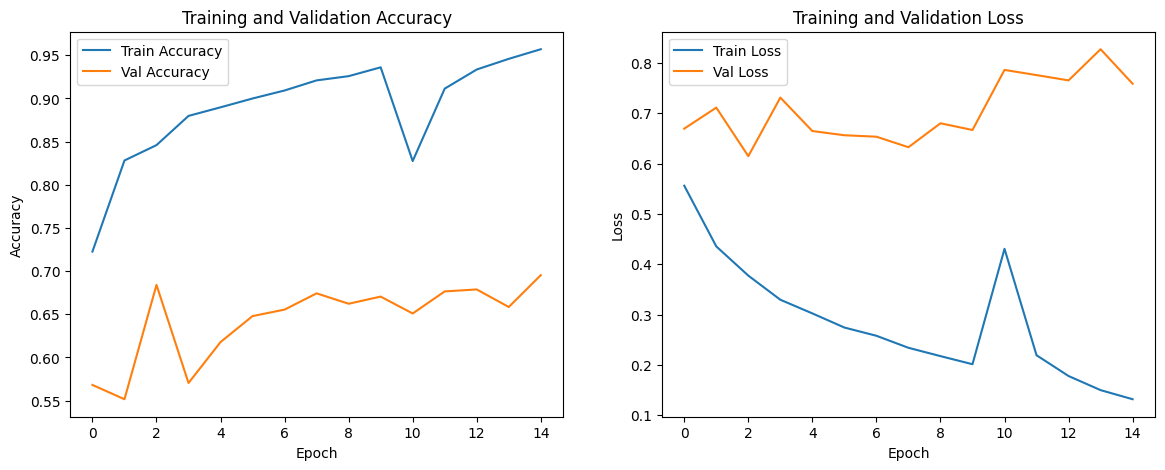

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

train_dir = '/kaggle/input/x-ray-dection/Bone Fracture Dataset/training'
test_dir = '/kaggle/input/x-ray-dection/Bone Fracture Dataset/testing'

# Image data generators
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.15,
    horizontal_flip=True,
    validation_split=0.15
)

test_datagen = ImageDataGenerator(rescale=1./255)

# Training generator with validation split
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training',
    shuffle=True
)

val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    shuffle=True
)

# Test generator
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Load base model DenseNet121 without top layers
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Add custom layers on top
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)

# Freeze base model layers for initial training
for layer in base_model.layers:
    layer.trainable = False

# Compile model
model.compile(optimizer=Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])

# Train model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

# Optionally unfreeze some layers and fine-tune
for layer in base_model.layers[-30:]:
    layer.trainable = True

model.compile(optimizer=Adam(learning_rate=1e-5), loss='binary_crossentropy', metrics=['accuracy'])

history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5
)

# Evaluate on test set
test_generator.reset()
Y_pred = model.predict(test_generator)
y_pred = (Y_pred > 0.5).astype(int).reshape(-1)
y_true = test_generator.classes

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)

# Classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=['not_fractured', 'fractured']))

# Plot training & validation accuracy/loss
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'] + history_fine.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'] + history_fine.history['val_accuracy'], label='Val Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'] + history_fine.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'] + history_fine.history['val_loss'], label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


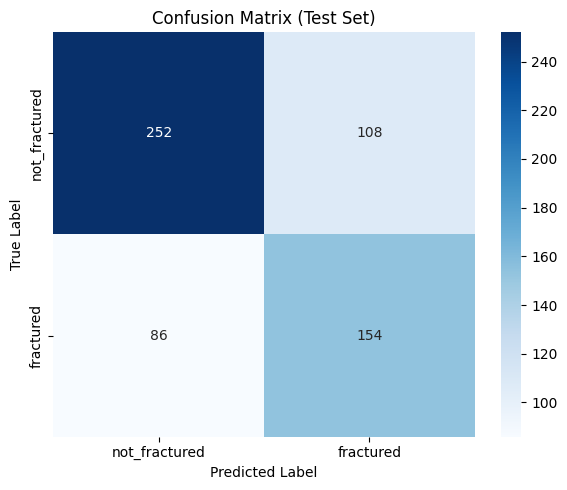

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ['not_fractured', 'fractured']

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix (Test Set)")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()

# Save the confusion matrix as an image
os.makedirs("results", exist_ok=True)
plt.savefig("results/test_confusion_matrix.png")

# Show the plot
plt.show()
